In [31]:
#defining true asteriod
%pip install zodipy
%pip install kete
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import kete

np.random.seed(42)


In [32]:
import pandas as pd
import numpy as np

from google.colab import drive
drive.mount('/content/drive')


import os
os.chdir('/content/drive/MyDrive/APEX')
df = pd.read_csv('neomod_atiras (10).csv')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [33]:
# Main-belt orbit
epoch = kete.Time.from_ymd(2024, 3, 15)
elements = kete.CometElements(
    desig="TestAsteroid",
    epoch=epoch,
    eccentricity=0.08,
    inclination=10.0,
    peri_arg=75.0,
    lon_of_ascending=45.0,
    peri_time=kete.Time(epoch.jd - 200),
    peri_dist=2.5,
)
state = elements.state
print(f"Orbit: a={elements.semi_major:.3f} AU, "
      f"e={elements.eccentricity:.3f}, "
      f"i={elements.inclination:.1f} deg")

Orbit: a=2.717 AU, e=0.080, i=10.0 deg


In [34]:

# 1. Load dataset and select target row
df = pd.read_csv("neomod_atiras (10).csv")
row = df.iloc[0]

# 2. Define true physical parameters
true_diam = float(row["diam_km"])
true_vis_albedo = float(row["albedo"])
true_h_mag = kete.compute_h_mag(true_diam, true_vis_albedo)
true_g_param = float(row.get("GS", 0.15))
true_emissivity = 0.9
true_beaming = 1.2
true_r_ir = 1.6
ir_albedo = true_r_ir * true_vis_albedo

# 3. Propagate orbit to generate target_positions and observer_positions
epoch = kete.Time.from_mjd(float(row["epochMJD_TDB"]))
n_deg_per_day = np.degrees(0.01720209895) / (float(row["a"]) ** 1.5)
peri_jd = epoch.jd - (float(row["ma"]) / n_deg_per_day)

elements = kete.CometElements(
    desig=str(row["ObjID"]),
    epoch=epoch,
    eccentricity=float(row["e"]),
    inclination=float(row["inc"]),
    peri_arg=float(row["argPeri"]),
    lon_of_ascending=float(row["node"]),
    peri_time=kete.Time(peri_jd),
    peri_dist=float(row["rp_au"]),
)
state = elements.state

obs_jds = epoch.jd + np.array([0, 1, 5, 6, 14, 15, 29, 30])
target_positions = []
observer_positions = []

for jd in obs_jds:
    target_positions.append(kete.propagate_two_body(state, jd).pos)
    observer_positions.append(kete.spice.get_state("Earth", jd).pos)

# 4. Compute model_outputs across all WISE bands
band_names = ["W1", "W2", "W3", "W4"]
model_outputs = [
    kete.flux.neatm_model_flux(
        sun2obj,
        sun2obs,
        band_albedos=[ir_albedo] * 4,
        h_mag=true_h_mag,
        vis_albedo=true_vis_albedo,
        diameter=true_diam,
        beaming=true_beaming,
        g_param=true_g_param,
        emissivity=true_emissivity,
        bands="wise",
    )
    for sun2obj, sun2obs in zip(target_positions, observer_positions)
]

# 5. Build observations (filter to ["W3", "W4"] for IR-only, or keep all 4 bands)
ir_only = True
fit_bands = ["W3", "W4"] if ir_only else band_names
observations = []

for idx, out in enumerate(model_outputs):
    sun2obj = list(target_positions[idx])
    sun2obs = list(observer_positions[idx])

    for band_idx, band in enumerate(band_names):
        if band not in fit_bands:
            continue

        true_flux = out.fluxes[band_idx]
        unc = max(0.05 * true_flux, 1e-6)

        obs = kete.flux.FluxObs(
            sun2obj=sun2obj,
            sun2obs=sun2obs,
            band=band,
            flux=true_flux,
            sigma=unc,
        )
        observations.append(obs)

# 6. Run MCMC NEATM fit constrained by optical H magnitude
result = kete.flux.fit_model(
    model="neatm",
    obs=observations,
    h_mag=true_h_mag,
    g_param=true_g_param,
    emissivity=true_emissivity,
    num_chains=4,
    num_tune=200,
    num_draws=500,
)


         Parameter   Median  Std Dev
     Diameter (km) 0.010447 0.000776
Visual Albedo (pV) 0.364024 0.098305
     Beaming (eta) 1.085576 0.235222
              R_IR 1.560928 0.255189
   IR Albedo (pIR) 0.559730 0.182830


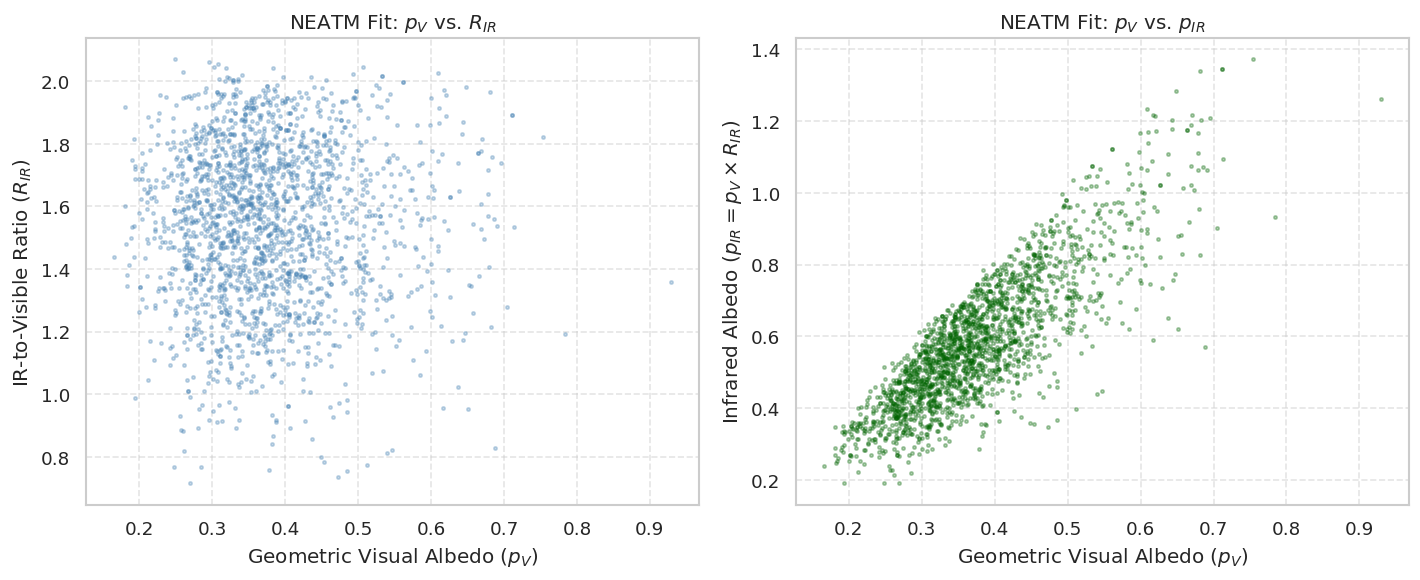

In [35]:
# 1. Extract MCMC posterior draws and column mapping from the kete fit result
draws = np.array(result.draws)
columns = result.columns

# Convert draws array into a structured pandas DataFrame
df_posterior = pd.DataFrame(draws, columns=columns)

# Calculate the explicit Infrared Albedo (p_IR = p_V * R_IR)
df_posterior["ir_albedo"] = (
    df_posterior["vis_albedo"] * df_posterior["ir_albedo_ratio"]
)

# Extract median and 95% confidence intervals from the fit summary object
summary_data = {
    "Parameter": ["Diameter (km)", "Visual Albedo (pV)", "Beaming (eta)", "R_IR", "IR Albedo (pIR)"],
    "Median": [
        result.diameter.median,
        result.vis_albedo.median,
        result.beaming.median,
        result.ir_albedo_ratio.median,
        np.median(df_posterior["ir_albedo"]),
    ],
    "Std Dev": [
        result.diameter.std,
        result.vis_albedo.std,
        result.beaming.std,
        result.ir_albedo_ratio.std,
        np.std(df_posterior["ir_albedo"]),
    ],
}
df_summary = pd.DataFrame(summary_data)
print(df_summary.to_string(index=False))

# 2. Plot Visual Albedo vs. IR-to-Visible Ratio & Calculated IR Albedo
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120)

# Plot 1: Geometric Visual Albedo (pV) vs IR-to-Visible Albedo Ratio (R_IR)
axes[0].scatter(
    df_posterior["vis_albedo"],
    df_posterior["ir_albedo_ratio"],
    s=4,
    alpha=0.3,
    color="steelblue",
)
axes[0].set_xlabel(r"Geometric Visual Albedo ($p_V$)")
axes[0].set_ylabel(r"IR-to-Visible Ratio ($R_{IR}$)")
axes[0].set_title(r"NEATM Fit: $p_V$ vs. $R_{IR}$")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Geometric Visual Albedo (pV) vs Calculated Infrared Albedo (p_IR)
axes[1].scatter(
    df_posterior["vis_albedo"],
    df_posterior["ir_albedo"],
    s=4,
    alpha=0.3,
    color="darkgreen",
)
axes[1].set_xlabel(r"Geometric Visual Albedo ($p_V$)")
axes[1].set_ylabel(r"Infrared Albedo ($p_{IR} = p_V \times R_{IR}$)")
axes[1].set_title(r"NEATM Fit: $p_V$ vs. $p_{IR}$")
axes[1].grid(True, linestyle="--", alpha=0.5)


plt.tight_layout()
plt.show()

In [39]:
# import matplotlib.pyplot as plt
# import pandas as pd
# import seaborn as sns

# # 1. Load the CSV dataset
# df = pd.read_csv("neomod_atiras (10).csv")

# # 2. Configure visualization style
# sns.set_theme(style="whitegrid")
# fig, axes = plt.subplots(2, 3, figsize=(15, 10), dpi=150)

# # Panel 1: Absolute Magnitude (H_V) vs. Semi-major Axis (a)
# sns.scatterplot(
#     data=df,
#     x="a",
#     y="H_V",
#     hue="albedo",
#     palette="viridis",
#     alpha=0.6,
#     s=15,
#     ax=axes[0, 0],
# )
# axes[0, 0].set_title(r"Absolute Magnitude ($H_V$) vs. Semi-major Axis ($a$)")
# axes[0, 0].set_xlabel(r"Semi-major Axis $a$ (au)")
# axes[0, 0].set_ylabel(r"Absolute Magnitude ($H_V$)")
# axes[0, 0].invert_yaxis()  # Brighter objects at top

# # Panel 2: Eccentricity (e) vs. Semi-major Axis (a)
# sns.scatterplot(
#     data=df,
#     x="a",
#     y="e",
#     hue="inc",
#     palette="magma",
#     alpha=0.6,
#     s=15,
#     ax=axes[0, 1],
# )
# axes[0, 1].set_title(r"Eccentricity ($e$) vs. Semi-major Axis ($a$)")
# axes[0, 1].set_xlabel(r"Semi-major Axis $a$ (au)")
# axes[0, 1].set_ylabel(r"Eccentricity ($e$)")

# # Panel 3: Inclination (inc) Distribution
# sns.histplot(df["inc"], kde=True, color="teal", bins=40, ax=axes[0, 2])
# axes[0, 2].set_title(r"Inclination ($inc$) Distribution")
# axes[0, 2].set_xlabel(r"Inclination (deg)")

# # Panel 4: Albedo Distribution
# sns.histplot(df["albedo"], kde=True, color="coral", bins=40, ax=axes[1, 0])
# axes[1, 0].set_title(r"Albedo Distribution")
# axes[1, 0].set_xlabel(r"Geometric Albedo")

# # Panel 5: Diameter Distribution (Log Scale)
# sns.histplot(
#     df["diam_km"],
#     kde=True,
#     color="purple",
#     bins=40,
#     log_scale=True,
#     ax=axes[1, 1],
# )
# axes[1, 1].set_title(r"Diameter ($diam\_km$) Distribution")
# axes[1, 1].set_xlabel(r"Diameter (km) [Log Scale]")

# # Panel 6: Photometric Color-Color Diagram (g-r vs i-r)
# sns.scatterplot(
#     data=df.sample(min(10000, len(df))),
#     x="g-r",
#     y="i-r",
#     alpha=0.3,
#     s=10,
#     color="darkblue",
#     ax=axes[1, 2],
# )
# axes[1, 2].set_title(r"Color-Color Diagram ($g-r$ vs $i-r$)")
# axes[1, 2].set_xlabel(r"$g - r$")
# axes[1, 2].set_ylabel(r"$i - r$")

# # Final adjustments and render
# plt.tight_layout()
# plt.show()

In [40]:


# Extract posterior draws from fit result
draws_df = pd.DataFrame(np.array(result.draws), columns=result.columns)

# Define custom Gaussian prior on beaming parameter eta ~ N(1.0, 0.25)
eta_prior = norm(loc=1.0, scale=0.25)

# Calculate sample likelihood weights with the prior applied
log_priors = eta_prior.logpdf(draws_df["beaming"])
weights = np.exp(log_priors - np.max(log_priors))

# Resample posterior draws according to prior weights
resampled_indices = np.random.choice(
    len(draws_df), size=len(draws_df), p=weights / weights.sum(), replace=True
)
weighted_posterior = draws_df.iloc[resampled_indices].reset_index(drop=True)

# Calculate explicit IR albedo on resampled posterior
weighted_posterior["ir_albedo"] = (
    weighted_posterior["vis_albedo"] * weighted_posterior["ir_albedo_ratio"]
)

# Export re-weighted posterior results
weighted_posterior.to_csv("neatm_ir_only_prior_draws.csv", index=False)

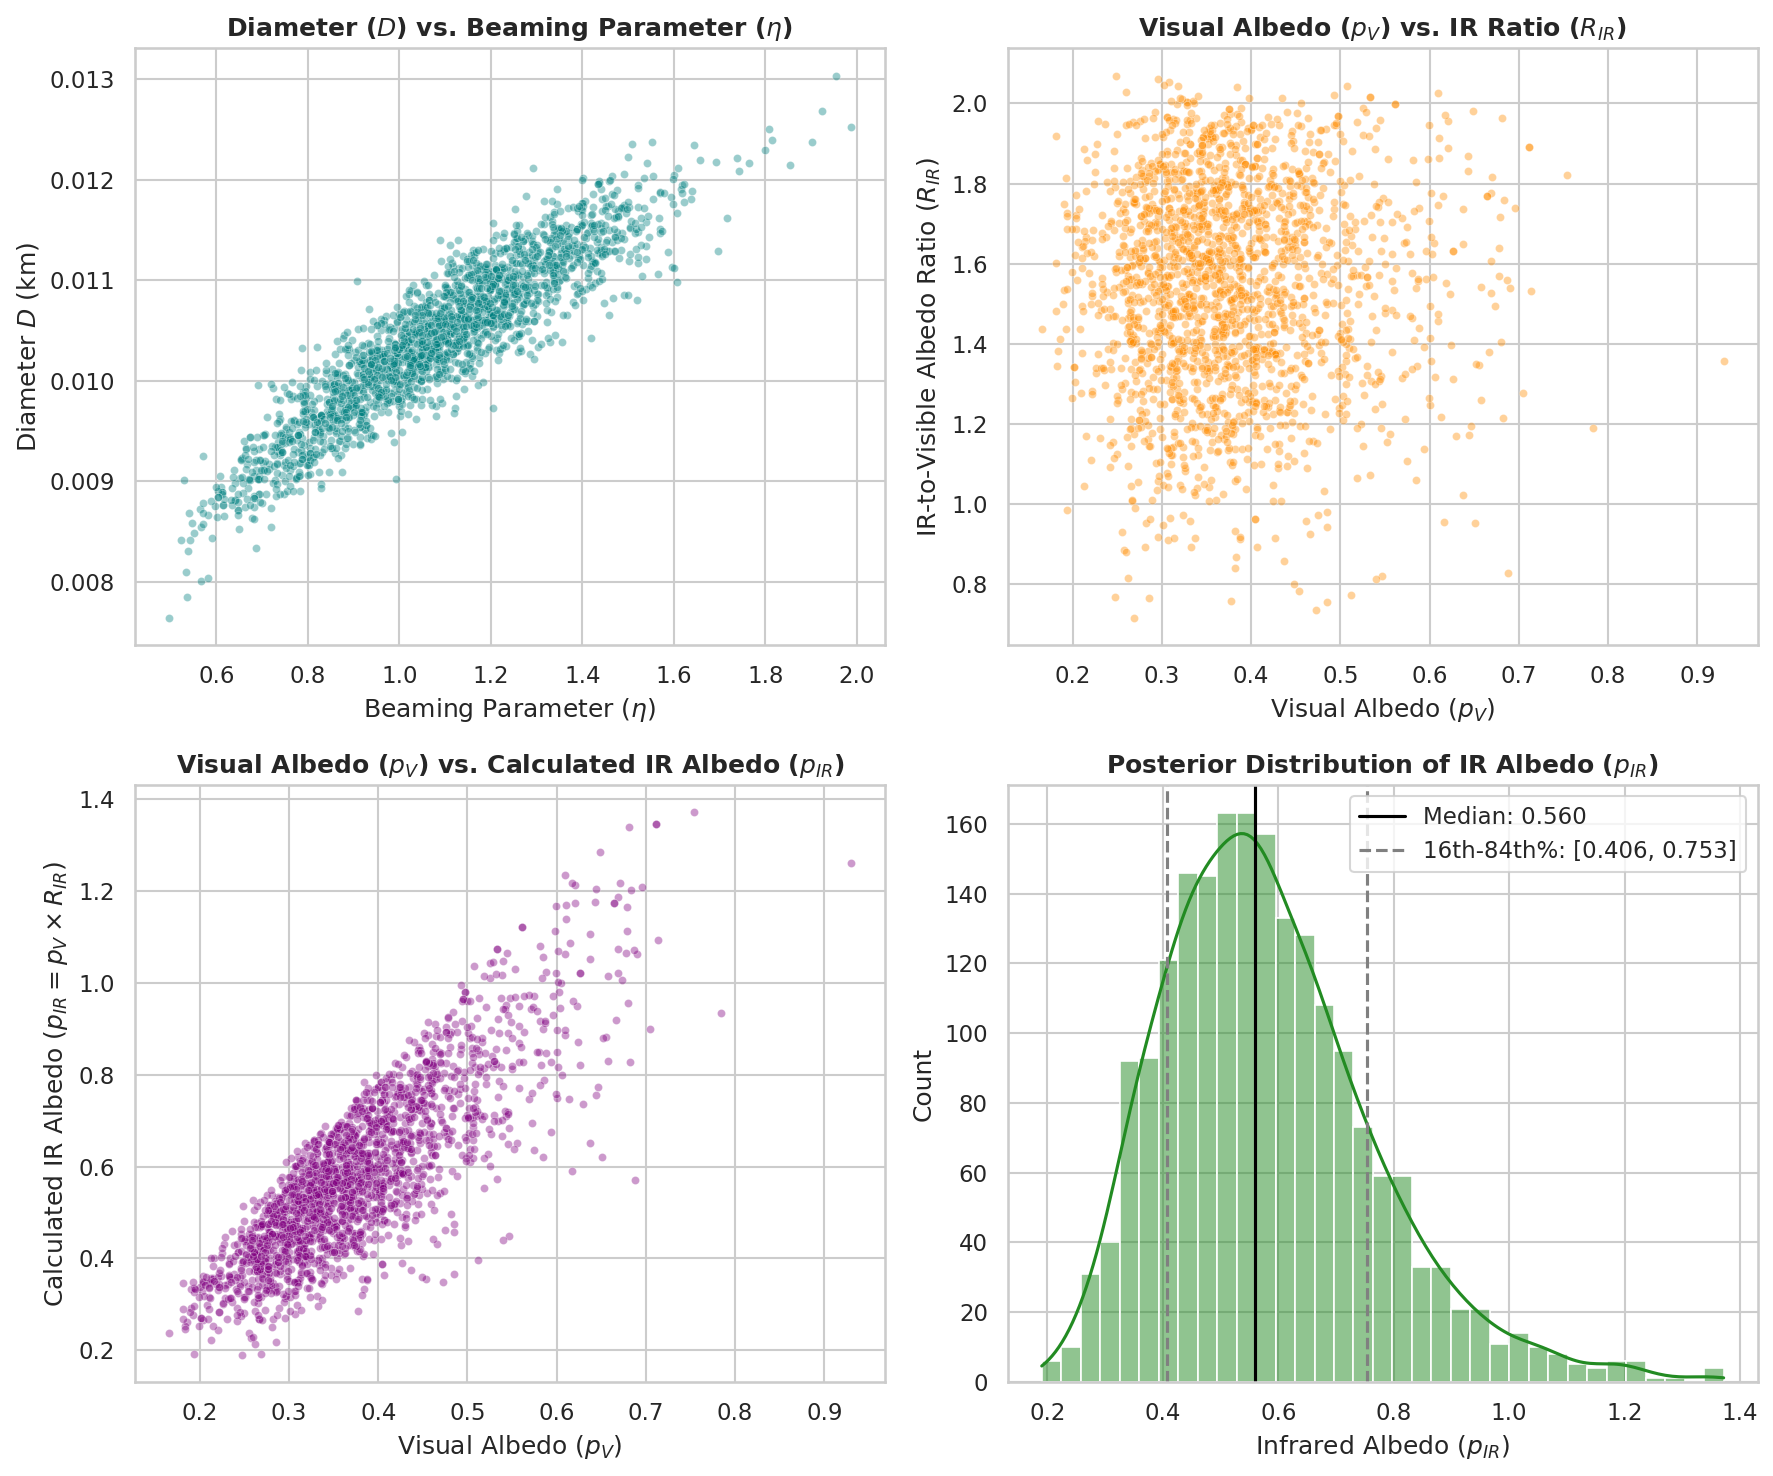

In [38]:
# 1. Extract MCMC posterior draws from kete NEATM fit
draws = np.array(result.draws)
columns = result.columns

df_posterior = pd.DataFrame(draws, columns=columns)

# Calculate explicit IR Albedo (p_IR = p_V * R_IR)
if "vis_albedo" in df_posterior.columns and "ir_albedo_ratio" in df_posterior.columns:
    df_posterior["ir_albedo"] = (
        df_posterior["vis_albedo"] * df_posterior["ir_albedo_ratio"]
    )

# 2. Multi-panel diagnostic plot layout
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(12, 10), dpi=150)

# Panel 1: Diameter vs Beaming Parameter (D vs eta)
sns.scatterplot(
    data=df_posterior,
    x="beaming",
    y="diameter",
    alpha=0.4,
    color="teal",
    s=15,
    ax=axes[0, 0],
)
axes[0, 0].set_title(
    r"Diameter ($D$) vs. Beaming Parameter ($\eta$)",
    fontsize=12,
    fontweight="bold",
)
axes[0, 0].set_xlabel(r"Beaming Parameter ($\eta$)")
axes[0, 0].set_ylabel(r"Diameter $D$ (km)")

# Panel 2: Visual Albedo vs IR Albedo Ratio (p_V vs R_IR)
sns.scatterplot(
    data=df_posterior,
    x="vis_albedo",
    y="ir_albedo_ratio",
    alpha=0.4,
    color="darkorange",
    s=15,
    ax=axes[0, 1],
)
axes[0, 1].set_title(
    r"Visual Albedo ($p_V$) vs. IR Ratio ($R_{IR}$)",
    fontsize=12,
    fontweight="bold",
)
axes[0, 1].set_xlabel(r"Visual Albedo ($p_V$)")
axes[0, 1].set_ylabel(r"IR-to-Visible Albedo Ratio ($R_{IR}$)")

# Panel 3: Visual Albedo vs Calculated IR Albedo (p_V vs p_IR)
sns.scatterplot(
    data=df_posterior,
    x="vis_albedo",
    y="ir_albedo",
    alpha=0.4,
    color="purple",
    s=15,
    ax=axes[1, 0],
)
axes[1, 0].set_title(
    r"Visual Albedo ($p_V$) vs. Calculated IR Albedo ($p_{IR}$)",
    fontsize=12,
    fontweight="bold",
)
axes[1, 0].set_xlabel(r"Visual Albedo ($p_V$)")
axes[1, 0].set_ylabel(r"Calculated IR Albedo ($p_{IR} = p_V \times R_{IR}$)")

# Panel 4: Posterior Distribution of Derived IR Albedo (p_IR)
sns.histplot(
    df_posterior["ir_albedo"],
    kde=True,
    color="forestgreen",
    bins=35,
    ax=axes[1, 1],
)
p16, p50, p84 = np.percentile(df_posterior["ir_albedo"], [16, 50, 84])
axes[1, 1].axvline(p50, color="black", linestyle="-", label=f"Median: {p50:.3f}")
axes[1, 1].axvline(
    p16,
    color="gray",
    linestyle="--",
    label=f"16th-84th%: [{p16:.3f}, {p84:.3f}]",
)
axes[1, 1].axvline(p84, color="gray", linestyle="--")
axes[1, 1].set_title(
    r"Posterior Distribution of IR Albedo ($p_{IR}$)",
    fontsize=12,
    fontweight="bold",
)
axes[1, 1].set_xlabel(r"Infrared Albedo ($p_{IR}$)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

In [38]:
import pandas as pd
import numpy as np

df = pd.read_csv('neomod_atiras (10).csv')
print("Shape:", df.shape)
print("Summary stats of albedo and colors:")
print(df[['albedo', 'g-r', 'i-r', 'z-r', 'u-r', 'y-r', 'diam_km', 'H_V']].describe())

# Check cluster separation in color-color or albedo
# Earlier plot showed two distinct clusters in g-r vs i-r! Let's check their bounds.
c1 = df[df['g-r'] < -0.70]
c2 = df[df['g-r'] >= -0.70]
print(f"\nCluster 1 (g-r < -0.70, C-like / low-albedo?): count={len(c1)}, mean albedo={c1['albedo'].mean():.4f}, median albedo={c1['albedo'].median():.4f}")
print(f"Cluster 2 (g-r >= -0.70, S-like / high-albedo?): count={len(c2)}, mean albedo={c2['albedo'].mean():.4f}, median albedo={c2['albedo'].median():.4f}")

                        albedo                                               p_IR                                                  R_IR                            diam_km                                              H_V                                                 g-r                                                      i-r                                                  
                         count      mean  median       std     min     max  count      mean   median       std      min      max  count mean median  std  min  max   count      mean  median       std   min     max  count       mean  median       std     min     max  count      mean    median       std       min       max  count      mean    median       std       min       max
cluster                                                                                                                                                                                                                                           

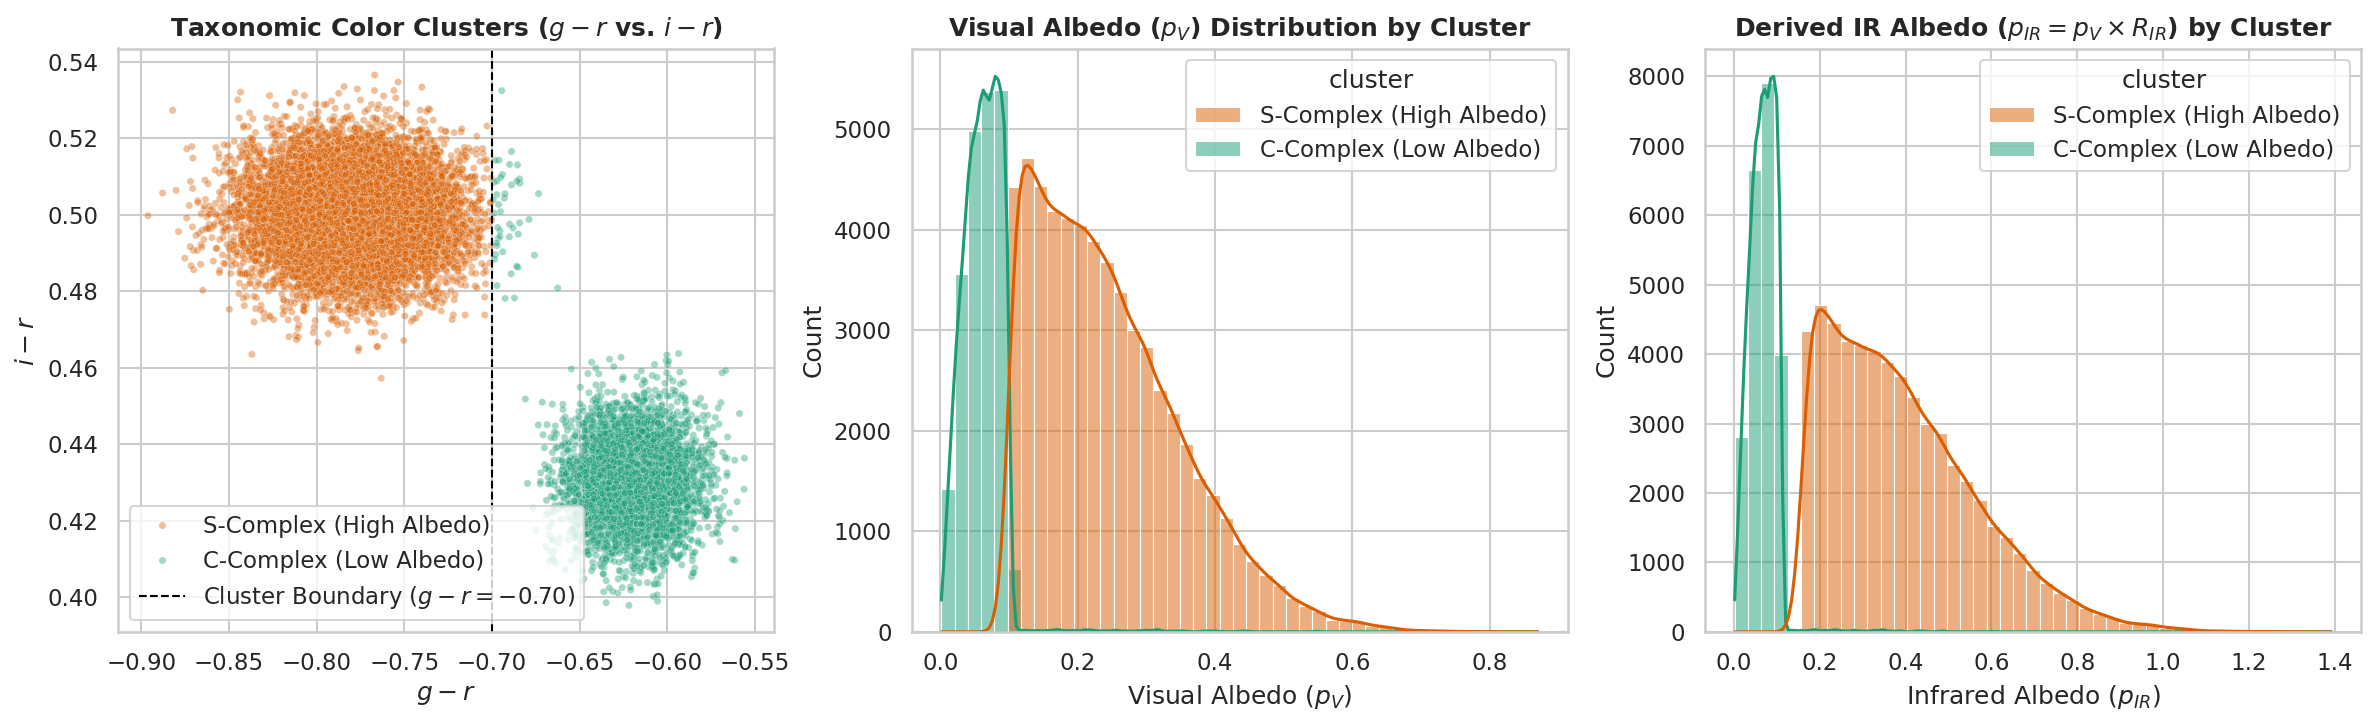

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('neomod_atiras (10).csv')

# Define clusters based on color-color separation (g-r < -0.70 vs g-r >= -0.70)
# Cluster 1: g-r < -0.70 (High albedo S-type / rocky complex, mean pV ~ 0.246, n = 57,111)
# Cluster 2: g-r >= -0.70 (Low albedo C-type / carbonaceous complex, mean pV ~ 0.062, n = 21,519)
df['cluster'] = np.where(df['g-r'] < -0.70, 'S-Complex (High Albedo)', 'C-Complex (Low Albedo)')

# Assign R_IR (IR-to-visible albedo ratio) based on taxonomic cluster / albedo regime
# S-types typically have higher R_IR (~1.5 - 1.6), C-types have lower R_IR (~1.0 - 1.2)
df['R_IR'] = np.where(df['cluster'] == 'S-Complex (High Albedo)', 1.6, 1.1)
df['p_IR'] = df['albedo'] * df['R_IR']
df['computed_diam_km'] = (1329.0 / np.sqrt(df['albedo'])) * (10.0 ** (-0.2 * df['H_V']))

# Compute summary statistics per cluster
summary = df.groupby('cluster')[['albedo', 'p_IR', 'R_IR', 'diam_km', 'H_V', 'g-r', 'i-r']].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
print(summary.to_string())

# Create a comparative visualization of Cluster vs Albedo & Derived IR Albedo (p_IR)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=150)

# Panel 1: Color-Color Cluster Separation
sample_df = df.sample(min(15000, len(df)), random_state=42)
sns.scatterplot(data=sample_df, x='g-r', y='i-r', hue='cluster', palette={'S-Complex (High Albedo)': '#d95f02', 'C-Complex (Low Albedo)': '#1b9e77'}, alpha=0.4, s=12, ax=axes[0])
axes[0].axvline(-0.70, color='black', linestyle='--', linewidth=1, label='Cluster Boundary ($g-r = -0.70$)')
axes[0].set_title('Taxonomic Color Clusters ($g-r$ vs. $i-r$)', fontweight='bold')
axes[0].set_xlabel('$g - r$')
axes[0].set_ylabel('$i - r$')
axes[0].legend()

# Panel 2: Visual Albedo (p_V) vs Derived IR Albedo (p_IR) by Cluster
sns.histplot(data=df, x='albedo', hue='cluster', palette={'S-Complex (High Albedo)': '#d95f02', 'C-Complex (Low Albedo)': '#1b9e77'}, bins=45, kde=True, alpha=0.5, ax=axes[1])
axes[1].set_title('Visual Albedo ($p_V$) Distribution by Cluster', fontweight='bold')
axes[1].set_xlabel('Visual Albedo ($p_V$)')

# Panel 3: Derived IR Albedo (p_IR = p_V * R_IR) by Cluster
sns.histplot(data=df, x='p_IR', hue='cluster', palette={'S-Complex (High Albedo)': '#d95f02', 'C-Complex (Low Albedo)': '#1b9e77'}, bins=45, kde=True, alpha=0.5, ax=axes[2])
axes[2].set_title('Derived IR Albedo ($p_{IR} = p_V \\times R_{IR}$) by Cluster', fontweight='bold')
axes[2].set_xlabel('Infrared Albedo ($p_{IR}$)')

plt.tight_layout()
plt.savefig('atira_clusters_ir_comparison.png')
plt.show()